In [164]:
import pandas as pd
import numpy as np
from src.data_preprocessing import preprocess
from src.hourly_grouping import build_session_hours
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

import warnings
warnings.filterwarnings("ignore")

In [165]:
df_raw = pd.read_csv("datasets/EVChargingStationUsage.csv")
df = preprocess(df_raw)
df.head(2)

[IDs -> strings]
[parse dates, drop invalid]
  dropped 249 rows with invalid or missing dates
[drop non-USD sessions and redundant columns]
  dropped 14 rows with currency MXN, EUR, CAD
  dropped columns: ['Country', 'Plug Type', 'Org Name', 'Currency', 'City', 'State/Province']
[clean station names]
[clean addresses]
[normalize MAC addresses]
[fill EVSE ID / Model Number from MAC]
  EVSE ID: filled 57,688 of 78,927 missing, 21,239 still missing
  Model Number: filled 57,688 of 78,927 missing, 21,239 still missing
[drop System S/N]
[fill missing categoricals with 'missing']
[add UTC columns]
[drop time zone mismatches]
  dropped 120 rows where start and end time zones are different
[validate durations and build duration columns]
  dropped 347 rows with missing or inconsistent duration (difference > 60 s)
[add time features]
[check Start <= End]
  OK: no rows with Start Date later than End Date
[remove outliers]
Sessions kept: 256,643 of 258,685 (failed plug-ins removed: 2,024, impossib

,Station Name,MAC Address,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),...,charging_duration_sec,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day,year,month,day_of_week
0,HAMILTON 1,000D6F00015A9D76,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,6.249457,...,6843.0,3.058889,1.900833,4169.0,1.158056,20,Evening,2011,7,4
1,HAMILTON 1,000D6F00015A9D76,2011-07-30 00:00:00,PDT,2011-07-30 00:02:00,PDT,2011-07-30 00:02:00,0:02:06,0:01:54,0.106588,...,114.0,0.035000,0.031667,12.0,0.003333,0,Night,2011,7,5


## Hourly intervals (from src/hourly_grouping)

In [167]:
hourly_events = build_session_hours(df)
hourly_events.head(10)

Hourly rows: 896,991 (on average 3.5 hours per session)


,session_id,User ID,Station Name,hour,occupied_h,charging_h,energy_kwh,idle_h
0,0,3284,HAMILTON 1,2011-07-29 20:00:00,0.716667,0.716667,2.356218,0.000000
1,0,3284,HAMILTON 1,2011-07-29 21:00:00,1.000000,1.000000,3.287746,0.000000
2,0,3284,HAMILTON 1,2011-07-29 22:00:00,1.000000,0.184167,0.605493,0.815833
3,0,3284,HAMILTON 1,2011-07-29 23:00:00,0.342222,0.000000,0.000000,0.342222
4,1,4169,HAMILTON 1,2011-07-30 00:00:00,0.035000,0.031667,0.106588,0.003333
5,2,4169,HAMILTON 1,2011-07-30 08:00:00,0.733333,0.733333,2.555198,0.000000
6,2,4169,HAMILTON 1,2011-07-30 09:00:00,1.000000,1.000000,3.484360,0.000000
7,2,4169,HAMILTON 1,2011-07-30 10:00:00,1.000000,1.000000,3.484360,0.000000
8,2,4169,HAMILTON 1,2011-07-30 11:00:00,1.000000,1.000000,3.484360,0.000000
9,2,4169,HAMILTON 1,2011-07-30 12:00:00,0.558889,0.557778,1.943499,0.001111


#### Quick analysus if the first sessions

First row from df - Hammilton 1, Start Date 2011-07-29 20:17, total duration sec 11012 (around 3h), charging duration 6843 (around 2h), energy 6.25. Then end of the charging would be 20:17 + 6843s = 22:11

20-21 (only 43 min = 0.71h) 

21- 22 (whole hour)

22-23 (only 11 min = 0.18h)

23-24 (only plugged in but not charging)

## User table - time preferences

In [174]:
def build_user_features(session_hours: pd.DataFrame, min_sessions: int = 10, verbose: bool = True) -> pd.DataFrame:
    blocks = ["night", "morning", "afternoon", "evening"]

    # 1. unknown users are not individual users
    unknown = session_hours["User ID"].isna() | session_hours["User ID"].isin(["missing", "0"])
    sh = session_hours.loc[~unknown].copy()

    # 2. keep users with enough sessions
    sessions_per_user = sh.groupby("User ID")["session_id"].nunique()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. timing: share of energy in each part of the day (hourly rows)
    sh["time_block"] = pd.cut(sh["hour"].dt.hour, [-1, 5, 11, 17, 23], labels=blocks)
    energy_total = sh.groupby("User ID")["energy_kwh"].sum()
    energy_by_block = (
        sh.groupby(["User ID", "time_block"], observed=False)["energy_kwh"].sum().unstack(fill_value=0)
    )
    shares = energy_by_block.div(energy_total, axis=0).add_prefix("share_energy_")
    # night is dropped: almost nobody charges at night (extremely skewed), and its share is
    # implied by the other three (night = 1 - morning - afternoon - evening)
    shares = shares.drop(columns="share_energy_night")

    # share of energy on Saturday and Sunday
    is_weekend = sh["hour"].dt.dayofweek >= 5
    energy_weekend = sh[is_weekend].groupby("User ID")["energy_kwh"].sum().reindex(energy_total.index, fill_value=0)
    shares["share_energy_weekend"] = energy_weekend / energy_total

    # 4. back to one row per session: typical charging and idle time, in minutes
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        occupied_h=("occupied_h", "sum"),
    )
    sess["charging_min"] = sess["charging_h"] * 60
    sess["idle_min"] = (sess["occupied_h"] - sess["charging_h"]) * 60
    by_user = sess.groupby("user")

    features = shares.join(pd.DataFrame({
        "median_charging_min": by_user["charging_min"].median(),
        "median_idle_min": by_user["idle_min"].median(),
    }))
    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,} "
              f"({len(keep) / len(sessions_per_user):.0%} of known users, "
              f"{sessions_per_user[keep].sum() / sessions_per_user.sum():.0%} of their sessions)")
        print(f"User features: {features.shape[0]:,} users x {features.shape[1]} features, "
              f"missing values: {int(features.isna().sum().sum())}")
    return features

In [175]:
user_features1 = build_user_features(hourly_events, min_sessions=10, verbose=True)
user_features1.head(3)

Users with at least 10 sessions: 3,579 (17% of known users, 84% of their sessions)
User features: 3,579 users x 6 features, missing values: 0


,share_energy_morning,share_energy_afternoon,share_energy_evening,share_energy_weekend,median_charging_min,median_idle_min
User ID,,,,,,
100243,0.079066,0.220512,0.607114,0.269483,143.666667,4.416667
100293,0.593211,0.038918,0.367870,0.613430,115.583333,33.233333
100523,0.124016,0.770184,0.105800,0.080989,94.441667,0.400000


## User table - intensity
(Experiments with different alternatives)

In [180]:
def build_user_features2(session_hours: pd.DataFrame,
                          min_sessions: int = 10,
                          verbose: bool = True) -> pd.DataFrame:

    # 1. Remove unknown users
    unknown = (
        session_hours["User ID"].isna() |
        session_hours["User ID"].isin(["missing", "0"])
    )
    sh = session_hours.loc[~unknown].copy()

    # 2. Keep users with enough sessions
    sessions_per_user = sh.groupby("session_id")["User ID"].first()
    sessions_per_user = sessions_per_user.value_counts()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. One row per session
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        energy_kwh=("energy_kwh", "sum")
    )

    # 4. Aggregate per user
    by_user = sess.groupby("user")

    features = pd.DataFrame({
        "n_sessions": by_user.size(),
        "total_energy_kwh": by_user["energy_kwh"].sum(),
        "median_energy_per_session": by_user["energy_kwh"].median(),
        "median_charging_min": by_user["charging_h"].median() * 60})

    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,}")
        print(f"User features A: {features.shape[0]:,} users x "
              f"{features.shape[1]} features, missing values: "
              f"{int(features.isna().sum().sum())}")

    return features

In [181]:
user_features2 = build_user_features2(hourly_events, min_sessions=10)
user_features2.head(3)

Users with at least 10 sessions: 3,579
User features A: 3,579 users x 4 features, missing values: 0


,n_sessions,total_energy_kwh,median_energy_per_session,median_charging_min
User ID,,,,
100243,649,5322.069112,7.407287,143.666667
100293,15,96.191890,6.336164,115.583333
100523,40,315.634840,7.343470,94.441667


<Axes: xlabel='total_energy_kwh', ylabel='Count'>

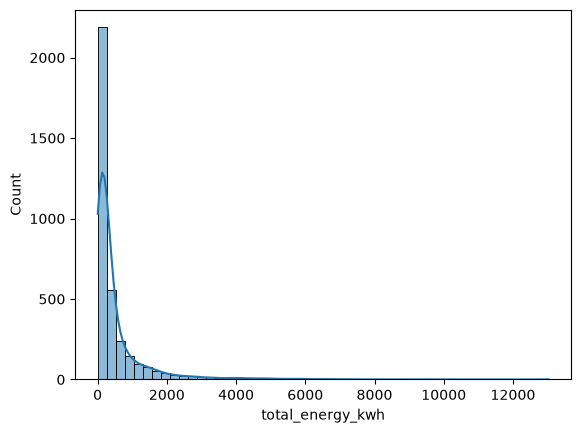

In [188]:
sns.histplot(
            user_features2["total_energy_kwh"],
            bins=50,
            kde=True,
        )

## User table 3 - effectiveness

In [206]:
def build_user_features3(session_hours: pd.DataFrame,
                          min_sessions: int = 10,
                          verbose: bool = True) -> pd.DataFrame:

    # 1. Remove unknown users
    unknown = (
        session_hours["User ID"].isna() |
        session_hours["User ID"].isin(["missing", "0"])
    )
    sh = session_hours.loc[~unknown].copy()

    # 2. Keep users with enough sessions
    sessions_per_user = sh.groupby("session_id")["User ID"].first()
    sessions_per_user = sessions_per_user.value_counts()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. One row per session
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        occupied_h=("occupied_h", "sum"),
        idle_h=("idle_h", "sum")
    )

    # Convert to minutes
    sess["charging_min"] = sess["charging_h"] * 60
    sess["occupied_min"] = sess["occupied_h"] * 60
    sess["idle_min"] = sess["idle_h"] * 60

    # Session-level ratios
    sess["charging_ratio"] = (
        sess["charging_h"] /
        sess["occupied_h"].replace(0, np.nan)
    )

    sess["idle_ratio"] = (
        sess["idle_h"] /
        sess["occupied_h"].replace(0, np.nan)
    )

    # 4. Aggregate per user
    by_user = sess.groupby("user")

    features = pd.DataFrame({
        "median_charging_min": by_user["charging_min"].median(),
        

        "median_occupied_min": by_user["occupied_min"].median(),
       

        "median_idle_min": by_user["idle_min"].median(),
        

        "median_charging_ratio": by_user["charging_ratio"].median(),
       
        "median_idle_ratio": by_user["idle_ratio"].median(),
        
    })

    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,}")
        print(f"User features B: {features.shape[0]:,} users x "
              f"{features.shape[1]} features, missing values: "
              f"{int(features.isna().sum().sum())}")

    return features

In [207]:
user_features3 = build_user_features3(hourly_events, min_sessions=10)
user_features3.head(3)

Users with at least 10 sessions: 3,579
User features B: 3,579 users x 5 features, missing values: 0


,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio
User ID,,,,,
100243,143.666667,176.733333,4.416667,0.971761,0.028239
100293,115.583333,156.633333,33.233333,0.773678,0.226322
100523,94.441667,99.258333,0.400000,0.995909,0.004091


<Axes: xlabel='median_charging_min', ylabel='Count'>

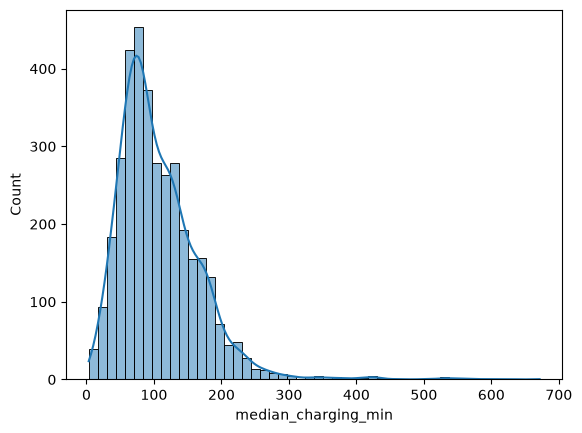

In [208]:
sns.histplot(
            user_features3["median_charging_min"],
            bins=50,
            kde=True,
        )

## K - Means 

Data preparation : log and Scaling

In [196]:
def K_means(dataset, LOG_FEATURES):
    X_raw = dataset.copy()
    print("Skośność przed:", X_raw.skew().round(2).to_dict())
    X_raw[LOG_FEATURES] = np.log1p(X_raw[LOG_FEATURES])
    print("Skośność po log1p:", X_raw[LOG_FEATURES].skew().round(2).to_dict())

    scaler = StandardScaler()
    X = pd.DataFrame(scaler.fit_transform(X_raw), index=X_raw.index, columns=X_raw.columns)
    assert not X.isna().any().any(), "są braki w cechach"
    print("Wejście do K-means:", X.shape)

    K_RANGE = range(2, 11)

    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        rows.append({
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "davies_bouldin": davies_bouldin_score(X, km.labels_),
        })

    k_scores = pd.DataFrame(rows).set_index("k")
    display(k_scores.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (col, title) in zip(axes, [
        ("inertia", "Inertia (szukaj łokcia)"),
        ("silhouette", "Silhouette (wyżej = lepiej)"),
        ("davies_bouldin", "Davies-Bouldin (niżej = lepiej)"),
    ]):
        ax.plot(k_scores.index, k_scores[col], marker="o")
        ax.set_title(title)
        ax.set_xlabel("K")
        ax.grid(True, alpha=0.3)
    sns.despine()
    plt.tight_layout()
    plt.show()

    return {
        "X_scaled": X,
        "X_transformed": X_raw,
        "scaler": scaler,
        "scores": k_scores
    }



In [198]:

def analyze_clusters(results, features_raw, K):
    
    # Scaled features from the previous function
    X_FINAL = results["X_scaled"]

    # Original features for cluster interpretation
    FEATURES = features_raw.loc[X_FINAL.index].copy()

    # Fit final K-means
    km_final = KMeans(
        n_clusters=K,
        n_init=50,
        random_state=42
    ).fit(X_FINAL)

    # Cluster labels
    labels = pd.Series(
        km_final.labels_,
        index=X_FINAL.index,
        name="Cluster"
    )

    # Centroids
    centroids = pd.DataFrame(
        km_final.cluster_centers_,
        columns=X_FINAL.columns
    ).rename_axis("klaster")

    # Metrics
    metrics = {
        "K": K,
        "silhouette": silhouette_score(X_FINAL, labels),
        "davies_bouldin": davies_bouldin_score(X_FINAL, labels),
        "inertia": km_final.inertia_
    }

    # Cluster profiles using original features
    prof = FEATURES.join(labels).groupby("Cluster").median()

    prof.insert(
        0,
        "users",
        labels.value_counts().sort_index()
    )

    prof.insert(
        1,
        "share_%",
        (100 * prof["users"] / prof["users"].sum()).round(1)
    )

    prof = prof.round(2)

    # Print metrics and profile
    print(f"--- K={K} ---")
    print(f"Silhouette: {metrics['silhouette']:.3f}")
    print(f"Davies-Bouldin: {metrics['davies_bouldin']:.3f}")
    print(f"Inertia: {metrics['inertia']:.2f}")

    display(prof)

    # Plot centroids
    fig, ax = plt.subplots(figsize=(10, 4))

    sns.heatmap(
        centroids,
        cmap="RdBu_r",
        center=0,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        ax=ax,
        cbar=False
    )

    ax.set_title(f"K={K} (z-score cech)")
    ax.set_ylabel("klaster")
    ax.tick_params(axis="x", rotation=35)

    plt.tight_layout()
    plt.show()

    return {
        "model": km_final,
        "labels": labels,
        "centroids": centroids,
        "profile": prof,
        "metrics": metrics
    }


Skośność przed: {'share_energy_morning': 1.09, 'share_energy_afternoon': 0.07, 'share_energy_evening': 0.8, 'share_energy_weekend': 0.81, 'median_charging_min': 2.14, 'median_idle_min': 9.25}
Skośność po log1p: {'median_idle_min': 1.73, 'median_charging_min': -0.52}
Wejście do K-means: (3579, 6)


,inertia,silhouette,davies_bouldin
k,,,
2,16387.046,0.241,1.655
3,13380.741,0.236,1.465
4,11393.557,0.235,1.397
5,10022.141,0.245,1.302
6,9209.241,0.227,1.321
7,8417.368,0.243,1.257
8,7736.376,0.253,1.217
9,7169.976,0.253,1.206
10,6655.034,0.241,1.205


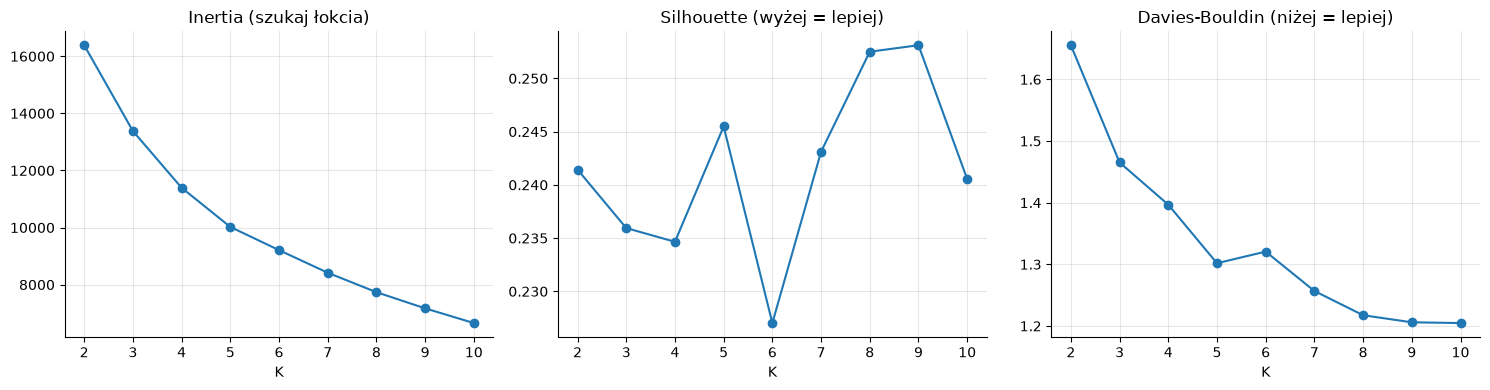

In [197]:
results1 = K_means(
    user_features1,
    LOG_FEATURES=["median_idle_min", "median_charging_min"]
)

--- K=5 ---
Silhouette: 0.246
Davies-Bouldin: 1.302
Inertia: 10022.11


,users,share_%,share_energy_morning,share_energy_afternoon,share_energy_evening,share_energy_weekend,median_charging_min,median_idle_min
Cluster,,,,,,,,
0,811,22.7,0.18,0.52,0.24,0.59,64.50,0.31
1,453,12.7,0.20,0.52,0.14,0.15,127.54,26.43
2,863,24.1,0.05,0.28,0.60,0.31,84.10,0.33
3,951,26.6,0.21,0.65,0.09,0.05,111.45,0.33
4,501,14.0,0.71,0.23,0.01,0.01,137.55,0.53


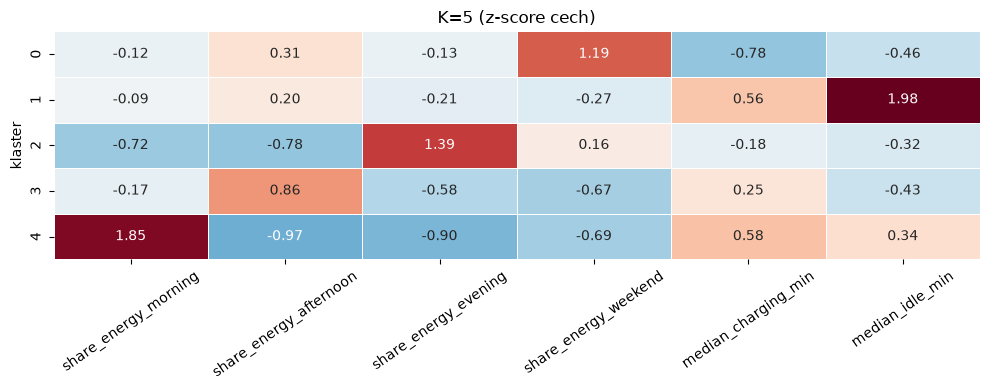

In [199]:
final1 = analyze_clusters(
    results=results1,
    features_raw=user_features1,
    K=5
)

Skośność przed: {'n_sessions': 4.73, 'total_energy_kwh': 5.02, 'median_energy_per_session': 2.64, 'median_charging_min': 2.14}
Skośność po log1p: {'total_energy_kwh': 0.54, 'median_energy_per_session': 0.07, 'median_charging_min': -0.52}
Wejście do K-means: (3579, 4)


,inertia,silhouette,davies_bouldin
k,,,
2,8413.277,0.398,0.997
3,6067.671,0.389,0.881
4,4606.642,0.338,0.921
5,3846.761,0.337,0.934
6,3295.451,0.298,0.971
7,2912.570,0.306,0.953
8,2623.772,0.288,0.963
9,2362.257,0.289,0.957
10,2200.348,0.290,0.948


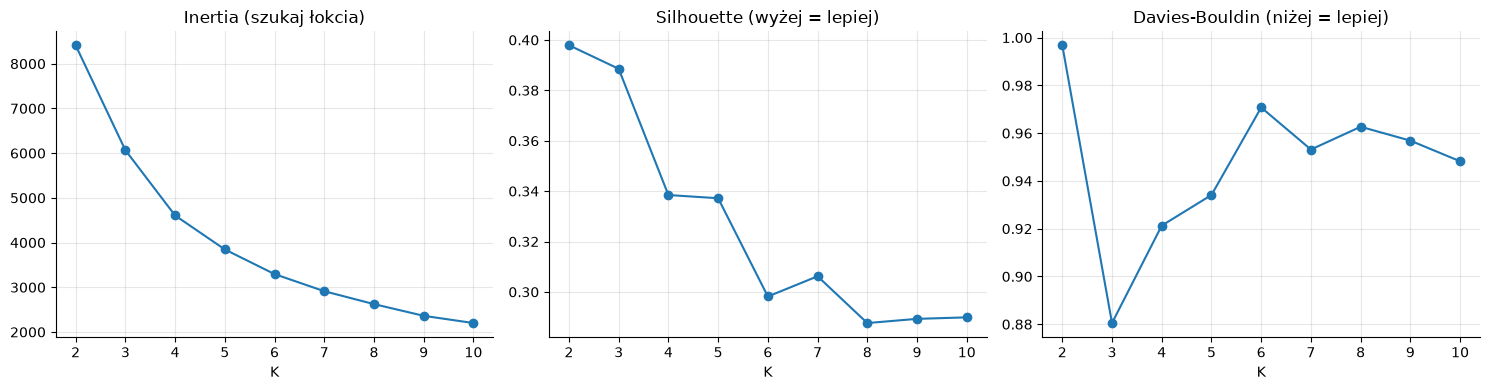

In [200]:
results2 =K_means(user_features2, LOG_FEATURES=[ "total_energy_kwh", "median_energy_per_session", "median_charging_min" ])

--- K=4 ---
Silhouette: 0.338
Davies-Bouldin: 0.921
Inertia: 4606.64


,users,share_%,n_sessions,total_energy_kwh,median_energy_per_session,median_charging_min
Cluster,,,,,,
0,1631,45.6,21.0,141.60,6.25,88.07
1,158,4.4,352.5,3201.19,8.58,131.58
2,772,21.6,18.0,59.82,2.84,47.28
3,1018,28.4,54.0,648.91,12.42,162.15


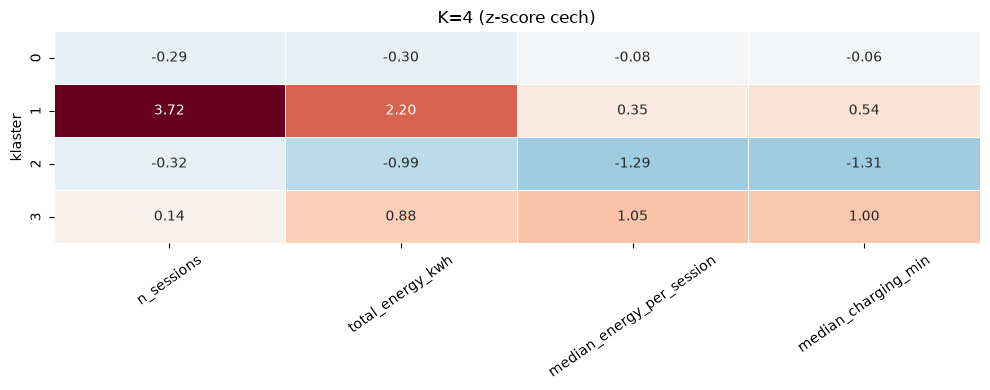

In [202]:
final2 = analyze_clusters(
    results=results2,
    features_raw=user_features2,
    K=4
)

Skośność przed: {'median_charging_min': 2.14, 'median_occupied_min': 2.9, 'median_idle_min': 9.25, 'median_charging_ratio': -3.39, 'median_idle_ratio': 3.39}
Skośność po log1p: {'median_charging_min': -0.52, 'median_occupied_min': -0.42, 'median_idle_min': 1.73, 'median_charging_ratio': -3.76, 'median_idle_ratio': 3.0}
Wejście do K-means: (3579, 5)


,inertia,silhouette,davies_bouldin
k,,,
2,9721.323,0.584,0.773
3,6178.489,0.446,0.750
4,4410.787,0.467,0.733
5,3324.234,0.463,0.709
6,2797.759,0.461,0.790
7,2380.375,0.426,0.780
8,2144.671,0.409,0.787
9,1928.937,0.410,0.802
10,1736.600,0.414,0.802


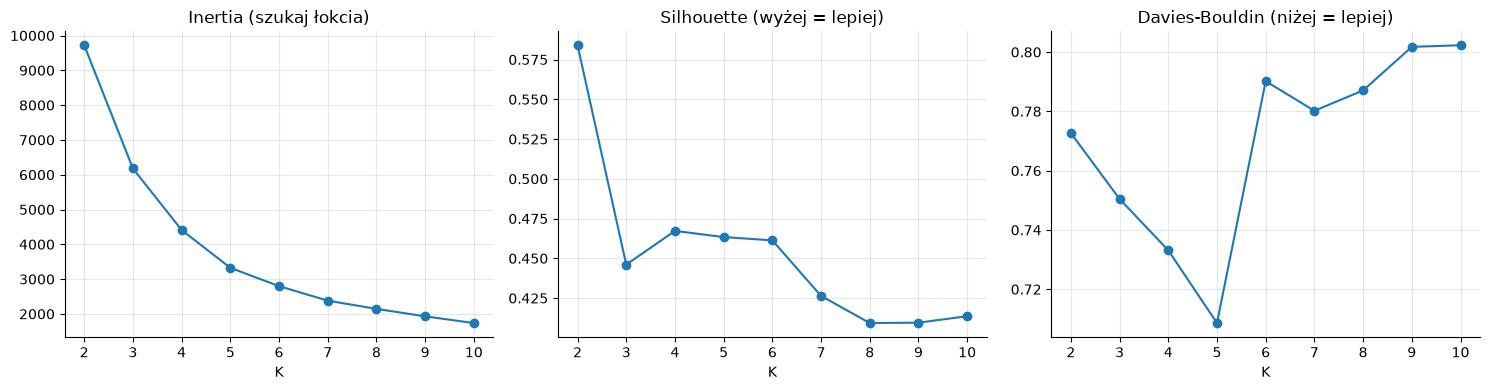

In [210]:
results3 = K_means(user_features3, LOG_FEATURES=[ "median_charging_min",  "median_occupied_min", "median_idle_min",  "median_charging_ratio",  "median_idle_ratio" ])

--- K=5 ---
Silhouette: 0.463
Davies-Bouldin: 0.709
Inertia: 3324.21


,users,share_%,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio
Cluster,,,,,,,
0,1056,29.5,153.34,163.78,0.36,1.00,0.00
1,434,12.1,39.37,42.18,0.30,0.99,0.01
2,149,4.2,99.25,184.62,74.72,0.56,0.44
3,1436,40.1,76.69,82.82,0.32,0.99,0.01
4,504,14.1,127.33,160.10,20.93,0.86,0.14


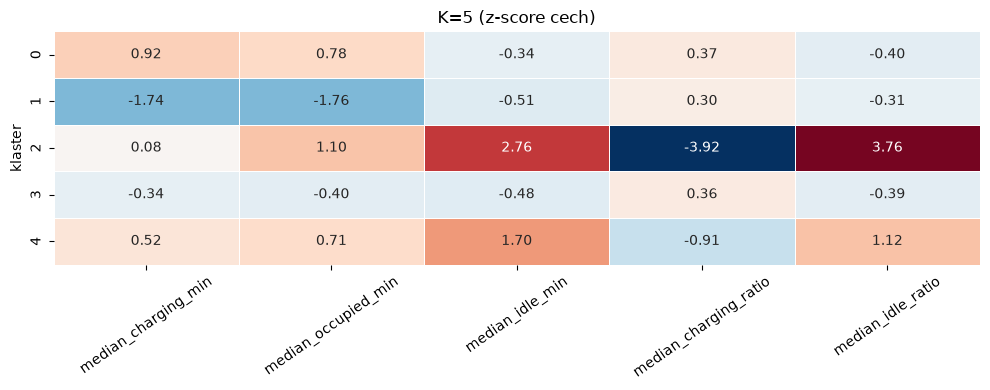

In [214]:
final3 = analyze_clusters(
    results=results3,
    features_raw=user_features3,
    K=5
) 
    

## Best one so far:

Silhouette is quite high 

Good cluster names (interpratation)

Cluster 0 : Long but efficient charging. These users charge for quite long, but charging time is mostly equal to total time 

Cluster 1: Short charging sessions with little idle time 

Cluster 2: Average charging time but a lot of idle minutes (idle dominated sessions)

Cluster 3: Regular,moderate users with regular charging time and not high idle minutes

Cluster 4: Long charging sessions with high idle. 

## Continue with cluster 3

In [ ]:
users_clustered_KMeans = user_features3.copy()

users_clustered_KMeans["Cluster"] = final3["labels"]

display(users_clustered_KMeans.head())

,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio,Cluster
User ID,,,,,,
100243,143.666667,176.733333,4.416667,0.971761,0.028239,0
100293,115.583333,156.633333,33.233333,0.773678,0.226322,4
100523,94.441667,99.258333,0.400000,0.995909,0.004091,3
100803,149.166667,162.925000,1.091667,0.988012,0.011988,0
1012301,78.033333,91.233333,7.400000,0.926475,0.073525,3


TO DO : cluster analysis based on other features in the dataset 

## TO DO : Try other clustering algorithms 